# Oral Diseases Image Classification

This project focuses on classifying oral diseases from images using deep learning.

The workflow covers dataset inspection, data quality analysis, image preprocessing, custom CNN development, transfer learning, model evaluation, and deployment.

## Make sure the data is available, and check the folder structure.

## 2. Dataset Inspection

### 2.1 Exploring the Dataset Directory Structure

This step explores the directory structure and counts the files in each directory to understand how the dataset is organized before performing data quality checks.

In [2]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root, len(files))

/kaggle/input 0
/kaggle/input/datasets 0
/kaggle/input/datasets/salmansajid05 0
/kaggle/input/datasets/salmansajid05/oral-diseases 0
/kaggle/input/datasets/salmansajid05/oral-diseases/Calculus 0
/kaggle/input/datasets/salmansajid05/oral-diseases/Calculus/Calculus 1296
/kaggle/input/datasets/salmansajid05/oral-diseases/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset 0
/kaggle/input/datasets/salmansajid05/oral-diseases/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset 0
/kaggle/input/datasets/salmansajid05/oral-diseases/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data 1
/kaggle/input/datasets/salmansajid05/oral-diseases/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images 0
/kaggle/input/datasets/salmansajid05/ora

## Determine the number of actual image files in each folder and provide examples of file names.
Based on this, we will identify the appropriate data folders and decide how to split the data into Training, Validation, and Test sets to prevent similar images from leaking between the sets.

### 2.2 Inspecting Image Folders

This step identifies directories containing image files and summarizes their contents.

For each directory containing images, it reports the number of images, file extensions, and sample filenames. This helps identify the dataset's folder structure, image formats, and potential differences between original and augmented datasets.

In [6]:
from pathlib import Path
from collections import Counter

dataset_path = Path("/kaggle/input/datasets/salmansajid05/oral-diseases")

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for folder in sorted(dataset_path.rglob("*")):
    if folder.is_dir():
        images = [
            file for file in folder.iterdir()
            if file.is_file() and file.suffix.lower() in image_extensions
        ]

        if images:
            print(f"\nFolder: {folder.relative_to(dataset_path)}")
            print(f"Image count: {len(images)}")
            print(f"Extensions: {dict(Counter(img.suffix.lower() for img in images))}")
            print(f"Examples: {[img.name for img in images[:3]]}")


Folder: Calculus/Calculus
Image count: 1296
Extensions: {'.jpg': 1296}
Examples: ['(1).jpg', '(10).jpg', '(100).jpg']

Folder: Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images/train
Image count: 1493
Extensions: {'.jpg': 864, '.jpeg': 629}
Examples: ['(1).jpg', '(10).jpg', '(100).jpg']

Folder: Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Caries_Gingivitus_ToothDiscoloration_Ulcer-yolo_annotated-Dataset/Data/images/val
Image count: 49
Extensions: {'.jpg': 49}
Examples: ['(225).jpg', '(226).jpg', '(227).jpg']

Folder: Data caries/Data caries/caries augmented data set/preview
Image count: 2382
Extensions: {'.jpeg': 2382}
Examples: ['caries_0_1001.jpeg', 'caries_0_1005.jpeg', 'caries_0_1006.jpeg']

Folder: Data caries/Data caries/caries orignal data set/done
Image count: 219
Extensions: {'.jpg': 219}
Examples: ['0.jpg', '1.jpg', '10.jpg']

Folder: Gingivitis/Gingivitis
Imag

### 2.3 Exact Duplicate and Cross-Class Conflict Detection

This step checks the selected original image folders for exact duplicate files using MD5 hashes.

It identifies:
- Duplicate image groups within and across classes.
- Images assigned to multiple classes, which may indicate conflicting labels.

The findings help assess data quality and reduce the risk of data leakage or misleading model evaluation. Conflicting labels will be investigated before deciding how to handle them.

In [8]:
from pathlib import Path
from collections import defaultdict
import hashlib

base = Path("/kaggle/input/datasets/salmansajid05/oral-diseases")

class_folders = {
    "Caries": base / "Data caries/Data caries/caries orignal data set/done",
    "Mouth Ulcer": base / "Mouth Ulcer/Mouth Ulcer/ulcer original dataset/ulcer original dataset",
    "Tooth Discoloration": base / "Tooth Discoloration/Tooth Discoloration /tooth discoloration original dataset/tooth discoloration original dataset",
    "Hypodontia": base / "hypodontia/hypodontia",
    "Gingivitis": base / "Gingivitis/Gingivitis",
    "Calculus": base / "Calculus/Calculus",
}

hash_locations = defaultdict(list)
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for class_name, folder in class_folders.items():
    for file in folder.iterdir():
        if file.is_file() and file.suffix.lower() in extensions:
            digest = hashlib.md5(file.read_bytes()).hexdigest()
            hash_locations[digest].append((class_name, file.name))

duplicates = {
    digest: locations
    for digest, locations in hash_locations.items()
    if len(locations) > 1
}

cross_class = {
    digest: locations
    for digest, locations in duplicates.items()
    if len({class_name for class_name, _ in locations}) > 1
}

print("Total images checked:", sum(map(len, hash_locations.values())))
print("Exact duplicate groups:", len(duplicates))
print("Duplicates across classes:", len(cross_class))

for locations in list(cross_class.values())[:10]:
    print(locations)

Total images checked: 5563
Exact duplicate groups: 775
Duplicates across classes: 392
[('Caries', '111.jpg'), ('Gingivitis', '(161).jpg')]
[('Caries', '117.jpg'), ('Caries', '90.jpg'), ('Gingivitis', '(202).jpg'), ('Calculus', '(24).jpg')]
[('Caries', '138.jpg'), ('Caries', '94.jpg'), ('Gingivitis', '(213).jpg'), ('Calculus', '(42).jpg')]
[('Caries', '144.jpg'), ('Caries', '87.jpg'), ('Gingivitis', '(121).jpg'), ('Gingivitis', '(186).jpg'), ('Calculus', '(138).jpg'), ('Calculus', '(4).jpg'), ('Calculus', '(95).jpg')]
[('Caries', '159.jpg'), ('Caries', '98.jpg'), ('Calculus', '(82).jpg')]
[('Caries', '168.jpg'), ('Gingivitis', '(101).jpg')]
[('Caries', '170.jpg'), ('Gingivitis', '(162).jpg'), ('Gingivitis', '(242).jpg'), ('Gingivitis', '(7).jpg'), ('Gingivitis', '(83).jpg'), ('Calculus', '(97).jpg')]
[('Caries', '173.jpg'), ('Calculus', '(113).jpg')]
[('Caries', '177.jpg'), ('Gingivitis', '(182).jpg')]
[('Caries', '181.jpg'), ('Calculus', '(45).jpg')]


### 2.4 Visual Inspection of Cross-Class Conflicts

This step visually inspects images whose identical file hashes appear under multiple class labels.

The notebook displays representative images alongside their associated labels to help verify whether the same image has been assigned to different classes.

Visual inspection supports informed data-cleaning decisions rather than removing or relabeling samples automatically.

Conflicting groups: 392


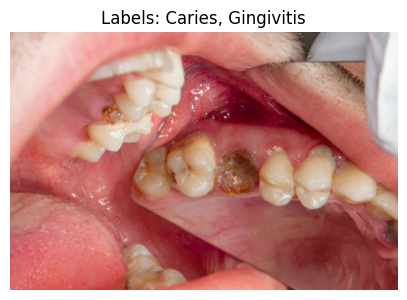

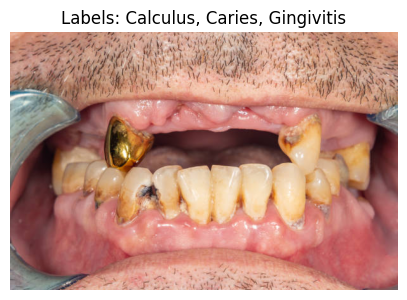

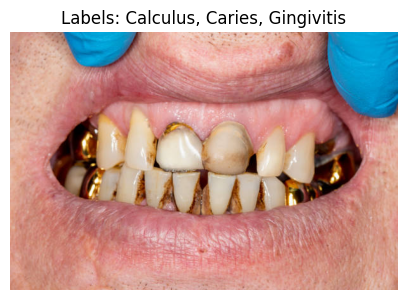

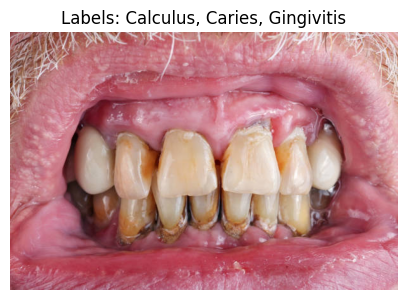

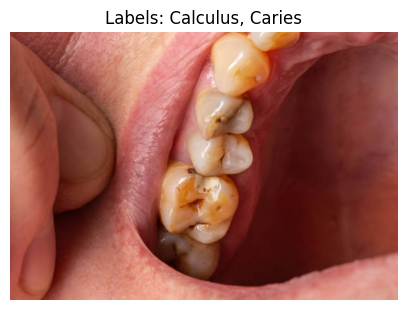

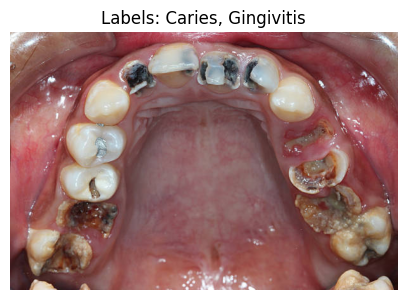

In [9]:
from pathlib import Path
from collections import defaultdict
from PIL import Image
import hashlib
import matplotlib.pyplot as plt

hash_paths = defaultdict(list)

for class_name, folder in class_folders.items():
    for file in folder.iterdir():
        if file.is_file() and file.suffix.lower() in extensions:
            digest = hashlib.md5(file.read_bytes()).hexdigest()
            hash_paths[digest].append((class_name, file))

cross_class_groups = [
    (digest, items)
    for digest, items in hash_paths.items()
    if len({name for name, _ in items}) > 1
]

print("Conflicting groups:", len(cross_class_groups))

for digest, items in cross_class_groups[:6]:
    class_names = sorted({name for name, _ in items})
    image_path = items[0][1]

    with Image.open(image_path) as img:
        plt.figure(figsize=(5, 4))
        plt.imshow(img.convert("RGB"))
        plt.title("Labels: " + ", ".join(class_names))
        plt.axis("off")
        plt.show()

### 2.5 Detailed Inspection of a Conflicting Image Group

This step examines the first detected cross-class conflict in detail.

For each file in the group, it reports the class label, filename, file size in bytes, and MD5 hash. Matching hashes confirm that the files have identical contents, even when their filenames or assigned classes differ.

This inspection provides evidence for investigating potential label conflicts before preparing the dataset for model training.

In [10]:
digest, items = cross_class_groups[0]

print("Same hash group:", digest)

for class_name, path in items:
    print(
        "Class:", class_name,
        "| File:", path.name,
        "| Size:", path.stat().st_size,
        "| Hash:", hashlib.md5(path.read_bytes()).hexdigest()
    )

Same hash group: a5771f1dd1dada718cec94c551182222
Class: Caries | File: 111.jpg | Size: 34826 | Hash: a5771f1dd1dada718cec94c551182222
Class: Gingivitis | File: (161).jpg | Size: 34826 | Hash: a5771f1dd1dada718cec94c551182222


### 2.6 Comparison of Duplicate Images

This step displays three files from the identified conflict group side by side.

The comparison helps visually verify the duplicate-image finding and illustrates how identical image content can appear under different filenames and class labels.

The observation will be considered alongside the hash-based analysis when deciding how to handle conflicting samples during dataset preparation.

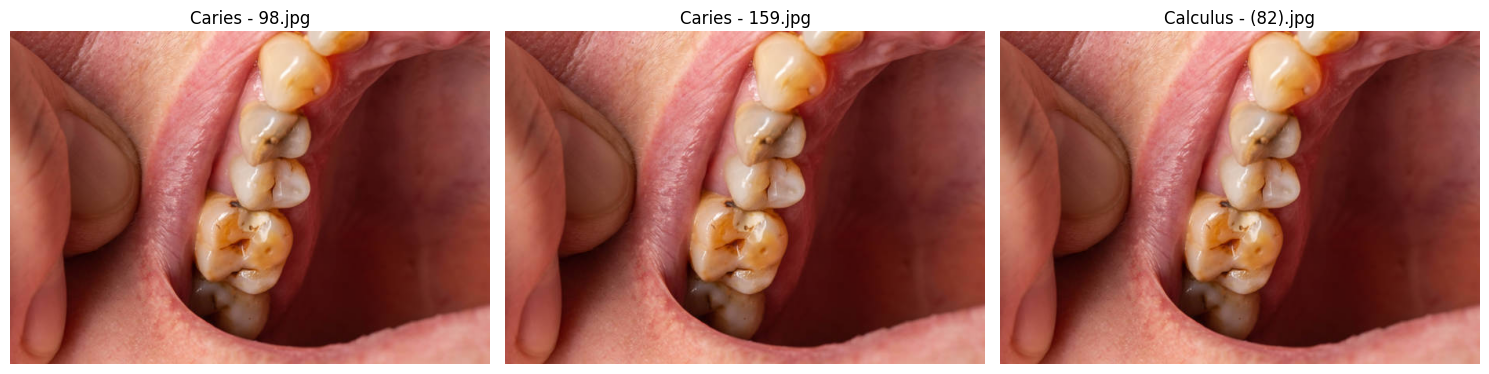

In [11]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

base = Path("/kaggle/input/datasets/salmansajid05/oral-diseases")

images = [
    ("Caries - 98.jpg",
     base / "Data caries/Data caries/caries orignal data set/done/98.jpg"),

    ("Caries - 159.jpg",
     base / "Data caries/Data caries/caries orignal data set/done/159.jpg"),

    ("Calculus - (82).jpg",
     base / "Calculus/Calculus/(82).jpg"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (title, path) in zip(axes, images):
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.7 Counting Unique Images per Class

This step counts unique images within each class using their MD5 hashes and identifies images that are assigned to multiple classes.

Using sets prevents identical files from being counted more than once within a class. The results help quantify duplicate images and potential label conflicts before dataset preparation.

In [12]:
from collections import defaultdict

unique_images_per_class = defaultdict(set)
classes_per_hash = defaultdict(set)

for class_name, folder in class_folders.items():
    for file in folder.iterdir():
        if file.is_file() and file.suffix.lower() in extensions:
            digest = hashlib.md5(file.read_bytes()).hexdigest()
            unique_images_per_class[class_name].add(digest)
            classes_per_hash[digest].add(class_name)

print("Unique images per class:")
for class_name, hashes in unique_images_per_class.items():
    print(f"{class_name}: {len(hashes)}")

print(
    "\nUnique images assigned to multiple classes:",
    sum(1 for labels in classes_per_hash.values() if len(labels) > 1)
)

Unique images per class:
Caries: 201
Mouth Ulcer: 243
Tooth Discoloration: 176
Hypodontia: 1242
Gingivitis: 1616
Calculus: 829

Unique images assigned to multiple classes: 392


### 2.8 Summary of Duplicate and Label Conflict Analysis

This step consolidates the duplicate-image analysis into a single summary.

It reports the total number of image files, the number of unique images across all classes, duplicate groups within the same class, and groups of identical images assigned to multiple classes.

These results provide an overview of the dataset's duplication and label consistency issues before selecting a data-cleaning strategy.

In [13]:
all_hashes = set()
same_class_duplicate_groups = 0
cross_class_groups = 0

for digest, items in hash_paths.items():
    all_hashes.add(digest)

    labels = {class_name for class_name, _ in items}

    if len(items) > 1 and len(labels) == 1:
        same_class_duplicate_groups += 1

    if len(labels) > 1:
        cross_class_groups += 1

print("Total image files:", sum(len(items) for items in hash_paths.values()))
print("Unique images across all classes:", len(all_hashes))
print("Duplicate groups within the same class:", same_class_duplicate_groups)
print("Conflicting groups across classes:", cross_class_groups)

Total image files: 5563
Unique images across all classes: 3899
Duplicate groups within the same class: 383
Conflicting groups across classes: 392


### 2.9 Estimating Usable Images After Excluding Label Conflicts

This step estimates the number of unique images remaining in each class after excluding images identified as cross-class conflicts.

The conflicting hashes are removed from each class's set of image hashes, providing an initial estimate of the data available for further preparation.

These counts are preliminary and will be used to guide the dataset-cleaning strategy.

In [14]:
conflicting_hashes = {
    digest
    for digest, items in hash_paths.items()
    if len({class_name for class_name, _ in items}) > 1
}

for class_name, folder in class_folders.items():
    class_hashes = {
        hashlib.md5(file.read_bytes()).hexdigest()
        for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in extensions
    }

    usable_hashes = class_hashes - conflicting_hashes

    print(
        f"{class_name}: "
        f"{len(usable_hashes)} images after excluding conflicts"
    )

Caries: 191 images after excluding conflicts
Mouth Ulcer: 243 images after excluding conflicts
Tooth Discoloration: 173 images after excluding conflicts
Hypodontia: 1215 images after excluding conflicts
Gingivitis: 1236 images after excluding conflicts
Calculus: 449 images after excluding conflicts


### 2.10 Analyzing Cross-Class Conflict Impact

This step counts the number of cross-class conflict groups affecting each class.

The results help identify which classes are most affected by duplicate images assigned to different labels and prioritize further investigation before data cleaning.

A conflict group may affect multiple classes, so the counts should not be summed to estimate the total number of distinct conflict groups.

In [15]:
from collections import Counter

conflict_impact = Counter()

for digest, items in hash_paths.items():
    labels = {class_name for class_name, _ in items}

    if len(labels) > 1:
        for class_name in labels:
            conflict_impact[class_name] += 1

print("Conflicting image groups affecting each class:")
for class_name, count in conflict_impact.most_common():
    print(f"{class_name}: {count}")

Conflicting image groups affecting each class:
Gingivitis: 380
Calculus: 380
Hypodontia: 27
Caries: 10
Tooth Discoloration: 3


### 2.11 Verifying a Gingivitis–Calculus Conflict Group

This step inspects a specific conflict group shared by the Gingivitis and Calculus classes.

It displays the file paths and image contents associated with the same hash to verify the duplicate detection result before making any data-cleaning decisions.

In [16]:
for digest, items in hash_paths.items():
    labels = {class_name for class_name, _ in items}

    if {"Gingivitis", "Calculus"}.issubset(labels):
        print("Hash:", digest)

        for class_name, path in items:
            print(f"Class: {class_name} | File: {path}")

        break

Hash: 9692880dfa75bedd69e7e4ee74d7c221
Class: Caries | File: /kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/117.jpg
Class: Caries | File: /kaggle/input/datasets/salmansajid05/oral-diseases/Data caries/Data caries/caries orignal data set/done/90.jpg
Class: Gingivitis | File: /kaggle/input/datasets/salmansajid05/oral-diseases/Gingivitis/Gingivitis/(202).jpg
Class: Calculus | File: /kaggle/input/datasets/salmansajid05/oral-diseases/Calculus/Calculus/(24).jpg


### 2.12 Visual Verification of a Multi-Class Conflict Group

This step displays all files belonging to a selected conflict group side by side.

The comparison verifies that the files contain identical image content despite having different filenames and class labels. The group will be investigated before deciding how to handle the conflicting labels.

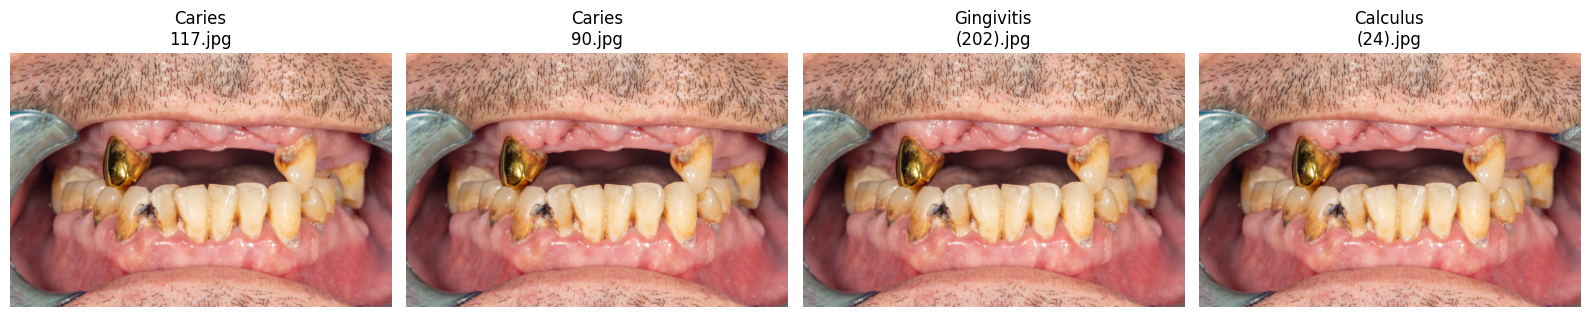

In [17]:
from PIL import Image
import matplotlib.pyplot as plt

digest = "9692880dfa75bedd69e7e4ee74d7c221"
items = hash_paths[digest]

fig, axes = plt.subplots(1, len(items), figsize=(16, 5))

for ax, (class_name, path) in zip(axes, items):
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(f"{class_name}\n{path.name}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### 2.13 Findings from Conflict Group Verification

Visual inspection confirmed that the four files in the selected conflict group contain identical image content, despite having different filenames.

The same image appears under three different class labels: Caries, Gingivitis, and Calculus.

This confirms a cross-class label conflict in the selected group. Since the correct label cannot be established from duplicate detection alone, the group should be excluded from model development unless a reliable source can verify its label.

The finding supports a conservative data-cleaning strategy to reduce label ambiguity and improve the reliability of model evaluation.

### 2.14 Identifying All Files in Cross-Class Conflict Groups

This step identifies every file belonging to a group of identical images assigned to multiple classes.

The resulting list will support data-cleaning decisions and help quantify the affected files before creating a cleaned dataset. The original dataset remains unchanged.

In [18]:
conflicting_files = []

for digest, items in hash_paths.items():
    labels = {class_name for class_name, _ in items}

    if len(labels) > 1:
        for class_name, path in items:
            conflicting_files.append({
                "hash": digest,
                "class": class_name,
                "path": path
            })

In [19]:
print("Total files in cross-class conflict groups:", len(conflicting_files))
print("Total conflicting groups:", cross_class_groups)

Total files in cross-class conflict groups: 1510
Total conflicting groups: 392


In [20]:
print("Total files in cross-class conflict groups:", len(conflicting_files))
print("Total conflicting groups:", len(cross_class_groups))

print("\nConflicting groups by number of files:")
group_sizes = [len(items) for _, items in cross_class_groups]

for size in sorted(set(group_sizes)):
    print(f"{size} files per group: {group_sizes.count(size)} groups")

Total files in cross-class conflict groups: 1510


TypeError: object of type 'int' has no len()

In [21]:
print("Unique images remaining per class:")

for class_name, hashes in unique_images_per_class.items():
    usable_hashes = {
        digest
        for digest in hashes
        if digest not in conflicting_hashes
    }

    print(f"{class_name}: {len(usable_hashes)}")

Unique images remaining per class:
Caries: 191
Mouth Ulcer: 243
Tooth Discoloration: 173
Hypodontia: 1215
Gingivitis: 1236
Calculus: 449


### 2.15 Measuring Class Imbalance

This step calculates the number and percentage of unique images in each class after excluding cross-class conflicts.

It also measures the ratio between the largest and smallest classes to quantify the degree of class imbalance before preparing the cleaned dataset.

In [22]:
class_counts = {
    class_name: len(hashes - conflicting_hashes)
    for class_name, hashes in unique_images_per_class.items()
}

total_images = sum(class_counts.values())

print(f"Total unique images: {total_images}")
print("\nClass distribution:")

for class_name, count in sorted(class_counts.items()):
    percentage = (count / total_images) * 100
    print(f"{class_name}: {count} images ({percentage:.2f}%)")

largest_class = max(class_counts, key=class_counts.get)
smallest_class = min(class_counts, key=class_counts.get)

imbalance_ratio = (
    class_counts[largest_class] / class_counts[smallest_class]
)

print(f"\nLargest class: {largest_class}")
print(f"Smallest class: {smallest_class}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}:1")

Total unique images: 3507

Class distribution:
Calculus: 449 images (12.80%)
Caries: 191 images (5.45%)
Gingivitis: 1236 images (35.24%)
Hypodontia: 1215 images (34.64%)
Mouth Ulcer: 243 images (6.93%)
Tooth Discoloration: 173 images (4.93%)

Largest class: Gingivitis
Smallest class: Tooth Discoloration
Imbalance ratio: 7.14:1


### 2.16 Visualizing Class Imbalance

This horizontal bar chart compares the number of unique images available in each class after excluding cross-class conflicts.

The visualization highlights the uneven class distribution and helps identify classes that may require special attention during model training and evaluation.

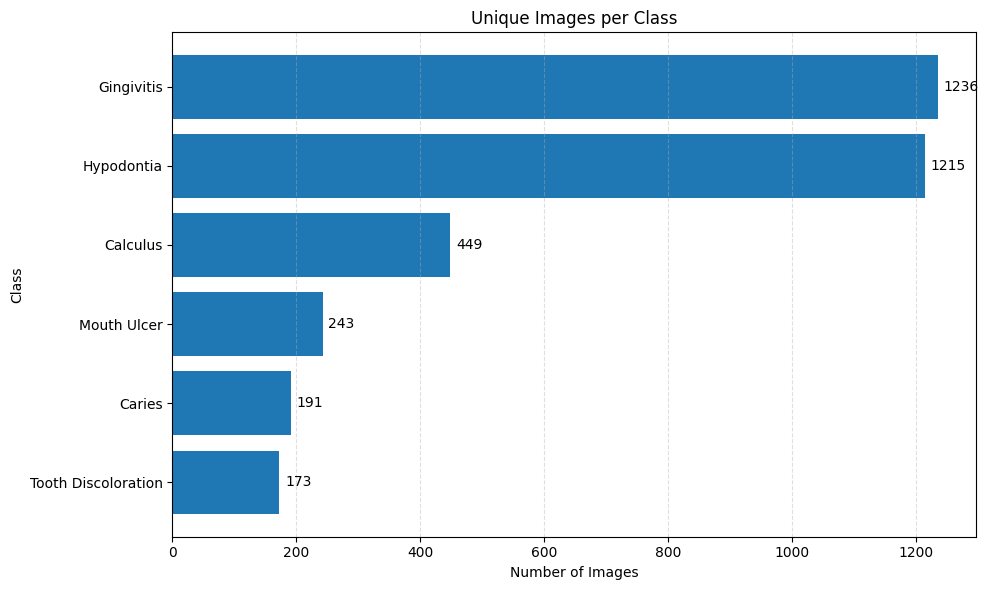

In [23]:
import matplotlib.pyplot as plt

sorted_counts = dict(
    sorted(class_counts.items(), key=lambda item: item[1])
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    list(sorted_counts.keys()),
    list(sorted_counts.values())
)

plt.bar_label(bars, padding=4)

plt.title("Unique Images per Class")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### 2.17 Analyzing Within-Class Duplicates

This step identifies exact duplicate images assigned to the same class.

It counts duplicate groups, total files involved, and redundant copies per class, excluding cross-class conflict groups. This analysis helps determine how many files can be removed from the derived dataset while preserving one copy of each valid image.

The original dataset remains unchanged.

In [24]:
from collections import Counter

duplicate_groups_per_class = Counter()
files_in_duplicate_groups = Counter()
redundant_copies_per_class = Counter()

for digest, items in hash_paths.items():
    labels = {class_name for class_name, _ in items}

    # Skip images assigned to multiple classes
    if len(labels) > 1:
        continue

    # Count duplicates within a single class
    if len(items) > 1:
        class_name = items[0][0]

        duplicate_groups_per_class[class_name] += 1
        files_in_duplicate_groups[class_name] += len(items)
        redundant_copies_per_class[class_name] += len(items) - 1

print("Within-class duplicate analysis")

for class_name in class_folders:
    print(
        f"{class_name}: "
        f"{duplicate_groups_per_class[class_name]} duplicate groups, "
        f"{files_in_duplicate_groups[class_name]} files involved, "
        f"{redundant_copies_per_class[class_name]} redundant copies"
    )

print("\n")
print("Total duplicate groups:", sum(duplicate_groups_per_class.values()))
print("Total files in duplicate groups:", sum(files_in_duplicate_groups.values()))
print("Total redundant copies:", sum(redundant_copies_per_class.values()))

Within-class duplicate analysis
Caries: 14 duplicate groups, 28 files involved, 14 redundant copies
Mouth Ulcer: 19 duplicate groups, 41 files involved, 22 redundant copies
Tooth Discoloration: 6 duplicate groups, 12 files involved, 6 redundant copies
Hypodontia: 9 duplicate groups, 18 files involved, 9 redundant copies
Gingivitis: 245 duplicate groups, 624 files involved, 379 redundant copies
Calculus: 90 duplicate groups, 206 files involved, 116 redundant copies


Total duplicate groups: 383
Total files in duplicate groups: 929
Total redundant copies: 546


### 2.18 Building the Clean Image Manifest

This step creates a manifest containing one representative file for each unique image that does not belong to a cross-class conflict group.

Within-class duplicates are reduced to one representative file, while conflicting image groups are excluded. The manifest preserves image paths and class labels without modifying the original dataset files.

In [25]:
from collections import Counter

clean_image_records = []

for digest, items in hash_paths.items():
    labels = {class_name for class_name, _ in items}

    # Exclude images assigned to multiple classes
    if len(labels) > 1:
        continue

    # Keep one representative file for each unique image
    class_name, path = items[0]

    clean_image_records.append({
        "hash": digest,
        "class": class_name,
        "path": path
    })

clean_counts = Counter(
    record["class"] for record in clean_image_records
)

print("Total clean unique images:", len(clean_image_records))
print("\nImages per class:")

for class_name in class_folders:
    print(f"{class_name}: {clean_counts[class_name]}")

Total clean unique images: 3507

Images per class:
Caries: 191
Mouth Ulcer: 243
Tooth Discoloration: 173
Hypodontia: 1215
Gingivitis: 1236
Calculus: 449


### 2.19 Preparing Stratified Data Splits

This step divides the cleaned image manifest into training, validation, and test sets using a 70:15:15 ratio.

Stratified splitting preserves the class distribution as closely as possible across the three subsets. A fixed random seed ensures reproducibility.

The split is performed on the manifest only; the original dataset files remain unchanged.

In [26]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Convert the clean manifest into a DataFrame
clean_df = pd.DataFrame(clean_image_records)

# Split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    clean_df,
    test_size=0.30,
    random_state=42,
    stratify=clean_df["class"]
)

# Split the temporary set equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["class"]
)

# Display split sizes
print("Dataset split summary")
print(f"Training images:   {len(train_df)}")
print(f"Validation images: {len(val_df)}")
print(f"Test images:       {len(test_df)}")
print(f"Total images:      {len(train_df) + len(val_df) + len(test_df)}")

# Display class distribution in each split
split_counts = pd.DataFrame({
    "Train": train_df["class"].value_counts(),
    "Validation": val_df["class"].value_counts(),
    "Test": test_df["class"].value_counts()
}).fillna(0).astype(int)

print("\nClass distribution by split:")
display(split_counts)

Dataset split summary
Training images:   2454
Validation images: 526
Test images:       527
Total images:      3507

Class distribution by split:


,Train,Validation,Test
class,,,
Gingivitis,865,185,186
Hypodontia,850,182,183
Calculus,314,67,68
Mouth Ulcer,170,37,36
Caries,134,29,28
Tooth Discoloration,121,26,26


### 2.20 Visualizing Data Augmentation

This step visualizes candidate data augmentation transformations on an image from the training set.

The purpose is to verify that the transformations introduce reasonable variation while preserving the visual characteristics relevant to oral disease classification. Augmentation is applied only to training images during model training, not to validation or test images.

I0000 00:00:1792851530.343043      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792851530.346977      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


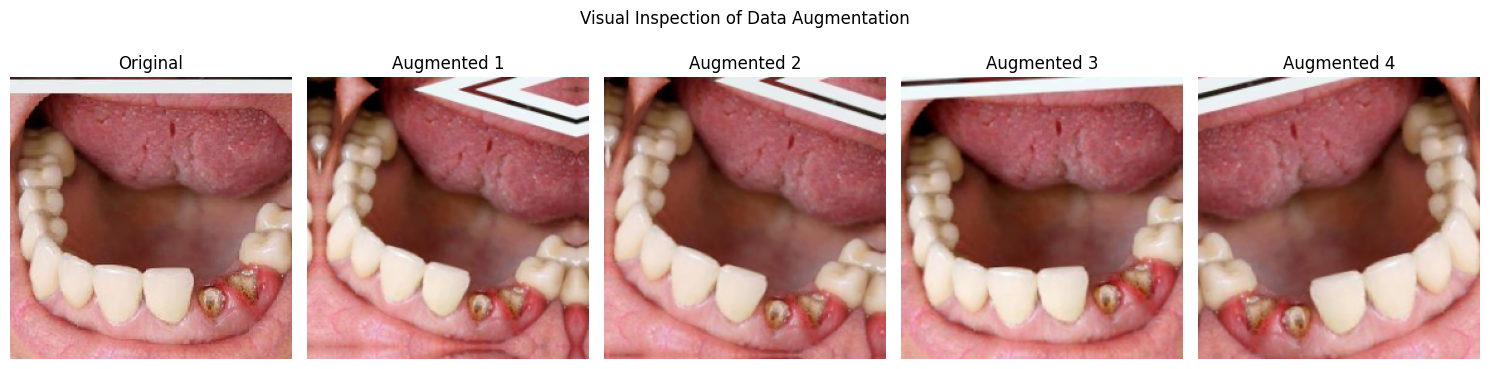

In [27]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

# Select one image from the training set
sample_path = train_df.iloc[0]["path"]
image = load_img(sample_path, target_size=(224, 224))
image = img_to_array(image)

# Define candidate augmentation transformations
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
])

# Display the original image and augmented versions
plt.figure(figsize=(15, 4))

plt.subplot(1, 5, 1)
plt.imshow(image.astype("uint8"))
plt.title("Original")
plt.axis("off")

for i in range(4):
    augmented_image = data_augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )[0].numpy()

    plt.subplot(1, 5, i + 2)
    plt.imshow(augmented_image.astype("uint8"))
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.suptitle("Visual Inspection of Data Augmentation")
plt.tight_layout()
plt.show()

### 2.21 Evaluating Training Class Imbalance

This step examines the number of training images in each class before augmentation.

The class distribution will guide the balancing strategy. Augmentation will be applied only to training images, while validation and test sets will remain unchanged to support fair model evaluation.

Training images per class:
class
Caries                 134
Mouth Ulcer            170
Tooth Discoloration    121
Hypodontia             850
Gingivitis             865
Calculus               314
Name: count, dtype: int64


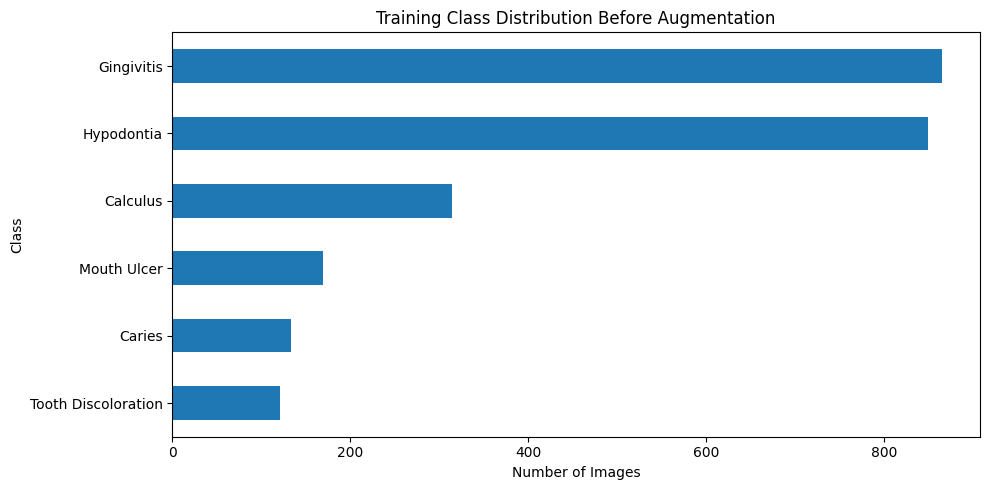

In [28]:
import matplotlib.pyplot as plt

train_counts = train_df["class"].value_counts().reindex(class_folders.keys())

print("Training images per class:")
print(train_counts)

plt.figure(figsize=(10, 5))
train_counts.sort_values().plot(kind="barh")
plt.title("Training Class Distribution Before Augmentation")
plt.xlabel("Number of Images")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

In [29]:
# Define the target number of samples per class
TARGET_PER_CLASS = 400

# Calculate the additional samples needed for each class
augmentation_plan = (
    train_df["class"]
    .value_counts()
    .reindex(class_folders.keys())
    .to_frame(name="Original")
)

augmentation_plan["Target"] = augmentation_plan["Original"].clip(
    upper=TARGET_PER_CLASS
).where(
    augmentation_plan["Original"] >= TARGET_PER_CLASS,
    TARGET_PER_CLASS
)

augmentation_plan["Additional Samples"] = (
    augmentation_plan["Target"] - augmentation_plan["Original"]
).clip(lower=0)

display(augmentation_plan)

,Original,Target,Additional Samples
class,,,
Caries,134,400,266
Mouth Ulcer,170,400,230
Tooth Discoloration,121,400,279
Hypodontia,850,400,0
Gingivitis,865,400,0
Calculus,314,400,86


### 2.22 Building the Balanced Training Pipeline

This step builds TensorFlow input pipelines for training, validation, and testing.

The training pipeline samples equally from all six classes. Images are loaded and augmented dynamically during training, allowing minority-class images to appear more frequently with varied transformations.

Validation and test images are resized but never augmented. All images retain their original class labels, and no image files are created or modified on disk.

In [30]:
import pandas as pd

target_count = 400
balanced_parts = []

for class_name in class_folders:
    class_df = train_df[train_df["class"] == class_name]

    if len(class_df) < target_count:
        extra_samples = class_df.sample(
            n=target_count - len(class_df),
            replace=True,
            random_state=42
        )

        class_df = pd.concat(
            [class_df, extra_samples],
            ignore_index=True
        )

    balanced_parts.append(class_df)

# Combine classes and shuffle the training records
balanced_train_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

# Verify the new distribution
balanced_counts = (
    balanced_train_df["class"]
    .value_counts()
    .reindex(class_folders.keys())
)

print("Training records before balancing:", len(train_df))
print("Training records after balancing:", len(balanced_train_df))

print("\nClass distribution after balancing:")
print(balanced_counts)

Training records before balancing: 2454
Training records after balancing: 3315

Class distribution after balancing:
class
Caries                 400
Mouth Ulcer            400
Tooth Discoloration    400
Hypodontia             850
Gingivitis             865
Calculus               400
Name: count, dtype: int64


### 2.23 Preparing the Image Input Pipeline

This step defines a consistent image-loading pipeline for the balanced training set and the original validation and test sets.

Images are resized to 224 × 224 pixels and converted to numerical arrays. Class labels are encoded consistently across all splits.

No augmentation is applied in this step. Augmentation will be introduced during model training only.

In [31]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.preprocessing import LabelEncoder

IMG_SIZE = (224, 224)

# Define a consistent class-to-index mapping
label_encoder = LabelEncoder()
label_encoder.fit(list(class_folders.keys()))

print("Class mapping:")
for class_name, index in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(f"{class_name}: {index}")


def load_images(dataframe):
    images = []
    labels = []

    for _, row in dataframe.iterrows():
        image = load_img(
            row["path"],
            target_size=IMG_SIZE,
            color_mode="rgb"
        )

        images.append(img_to_array(image))
        labels.append(row["class"])

    X = np.asarray(images, dtype=np.float32)
    y = label_encoder.transform(labels)

    return X, y


print("\nInput pipeline function defined successfully.")

Class mapping:
Calculus: 0
Caries: 1
Gingivitis: 2
Hypodontia: 3
Mouth Ulcer: 4
Tooth Discoloration: 5

Input pipeline function defined successfully.


### 2.24 Testing the Image Loading Function

This step tests the image-loading function using one image from each class.

We verify the resulting image tensor shape, label encoding, pixel value range, and class mapping before processing the complete datasets.

In [32]:
# Select one image from each class
sample_records = (
    train_df.groupby("class", group_keys=False)
    .head(1)
    .reset_index(drop=True)
)

# Load the sample images
X_sample, y_sample = load_images(sample_records)

print("Image tensor shape:", X_sample.shape)
print("Labels shape:", y_sample.shape)
print("Pixel value range:", X_sample.min(), "to", X_sample.max())

print("\nSample labels:")
for class_name, label in zip(sample_records["class"], y_sample):
    print(f"{class_name}: {label}")

Image tensor shape: (6, 224, 224, 3)
Labels shape: (6,)
Pixel value range: 0.0 to 255.0

Sample labels:
Hypodontia: 3
Gingivitis: 2
Caries: 1
Mouth Ulcer: 4
Calculus: 0
Tooth Discoloration: 5


### 2.25 Building a TensorFlow Image Dataset

This step creates a reusable TensorFlow dataset pipeline that loads images from file paths in batches rather than loading the entire dataset into memory.

The pipeline decodes images as RGB, resizes them to 224 × 224 pixels, and pairs each image with its encoded class label. Augmentation and model-specific preprocessing will be added later.

In [33]:
import tensorflow as tf

AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32


def decode_and_resize(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    return image, label


def build_dataset(dataframe, batch_size= BATCH_SIZE, shuffle=False):
    paths = dataframe["path"].astype(str).to_numpy()
    labels = label_encoder.transform(
        dataframe["class"].to_numpy()
    )

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        decode_and_resize,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


print("TensorFlow dataset pipeline defined successfully.")

TensorFlow dataset pipeline defined successfully.


### 2.26 Testing the TensorFlow Dataset Pipeline

This step validates the TensorFlow input pipeline using a small sample from the training set.

We verify the batch dimensions, label dimensions, pixel value range, and label values before building the complete datasets.

In [34]:
# Select one image from each class
sample_records = (
    train_df.groupby("class", group_keys=False)
    .head(1)
    .reset_index(drop=True)
)

# Build a small dataset
sample_dataset = build_dataset(
    sample_records,
    batch_size=6,
    shuffle=False
)

# Read the first batch
for images, labels in sample_dataset.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print(
        "Pixel value range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )
    print("Encoded labels:", labels.numpy())

Image batch shape: (6, 224, 224, 3)
Label batch shape: (6,)
Pixel value range: 0.0 to 255.0
Encoded labels: [3 2 1 4 0 5]


### 2.27 Building the Training, Validation, and Test Datasets

This step creates TensorFlow datasets for all three data splits.

The balanced training manifest is used for training, while the original validation and test manifests are preserved. Training data is shuffled, and all datasets are processed in batches with prefetching to improve input efficiency.

No augmentation or model-specific normalization is applied at this stage.

In [35]:
# Build the three datasets
train_dataset = build_dataset(
    balanced_train_df,
    shuffle=True
)

val_dataset = build_dataset(
    val_df,
    shuffle=False
)

test_dataset = build_dataset(
    test_df,
    shuffle=False
)

print("Training records:", len(balanced_train_df))
print("Validation records:", len(val_df))
print("Test records:", len(test_df))

print("\nDatasets created successfully.")

Training records: 3315
Validation records: 526
Test records: 527

Datasets created successfully.


### 2.28 Validating the Dataset Batches

This step checks the first batch from each dataset to verify image dimensions, label dimensions, and batch sizes.

The check confirms that the input pipeline produces compatible tensors before model development begins.

In [36]:
for dataset_name, dataset in [
    ("Training", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset)
]:
    images, labels = next(iter(dataset))

    print(f"\n{dataset_name} dataset")
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image dtype:", images.dtype)
    print("Label dtype:", labels.dtype)


Training dataset
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>

Validation dataset
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>

Test dataset
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image dtype: <dtype: 'float32'>
Label dtype: <dtype: 'int64'>


### 2.29 Defining the Custom CNN Augmentation Pipeline

This step defines the augmentation layers that will be used by the Custom CNN during training.

The augmentation layers apply random horizontal flips, rotations, zoom, and contrast adjustments. They remain inactive during validation and inference.

Pixel normalization will be handled separately in the model pipeline.

In [37]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1)
], name="data_augmentation")

print("Augmentation pipeline defined successfully.")

Augmentation pipeline defined successfully.


### 2.30 Testing the Augmentation Pipeline

This step applies the augmentation layers to a small batch of training images.

We verify that augmentation preserves the image tensor dimensions and produces valid pixel values. The original dataset and the validation and test sets remain unchanged.

In [38]:
# Get one batch from the training dataset
images, labels = next(iter(train_dataset))

# Apply augmentation to this batch
augmented_images = data_augmentation(
    images,
    training=True
)

print("Original batch shape:", images.shape)
print("Augmented batch shape:", augmented_images.shape)

print(
    "Original pixel range:",
    float(tf.reduce_min(images)),
    "to",
    float(tf.reduce_max(images))
)

print(
    "Augmented pixel range:",
    float(tf.reduce_min(augmented_images)),
    "to",
    float(tf.reduce_max(augmented_images))
)

Original batch shape: (32, 224, 224, 3)
Augmented batch shape: (32, 224, 224, 3)
Original pixel range: 0.0 to 255.0
Augmented pixel range: 0.0 to 255.0


### 2.31 Building the Custom CNN Baseline

This step defines a custom Convolutional Neural Network (CNN) for six-class oral disease image classification.

The model includes data augmentation, pixel rescaling, convolutional feature extraction, pooling, dropout, and a six-unit output layer.

The model will be compiled before training. Validation and test data will not receive random augmentation.

In [39]:
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = len(class_folders)

custom_cnn = keras.Sequential([
    keras.Input(shape=(224, 224, 3)),

    # Apply augmentation only during training
    data_augmentation,

    # Convert pixel values from [0, 255] to [0, 1]
    layers.Rescaling(1.0 / 255),

    # Convolutional block 1
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    # Convolutional block 2
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    # Convolutional block 3
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(NUM_CLASSES, activation="softmax")
], name="custom_cnn")

custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

custom_cnn.summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

### 2.32 Configuring Training Callbacks

This step defines callbacks to monitor validation performance during training.

Early stopping halts training when validation loss stops improving, while model checkpointing saves the model with the lowest validation loss.

These callbacks help reduce unnecessary training and preserve the best-performing model checkpoint.

In [40]:
from pathlib import Path

checkpoint_dir = Path("/kaggle/working/oral_disease_models")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

checkpoint_path = checkpoint_dir / "custom_cnn_best.keras"

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Training callbacks configured.")
print("Checkpoint path:", checkpoint_path)

Training callbacks configured.
Checkpoint path: /kaggle/working/oral_disease_models/custom_cnn_best.keras


### 2.33 Training the Custom CNN Baseline

This step trains the custom CNN using the balanced training dataset and monitors performance on the original validation dataset.

Training augmentation is applied within the model, while validation images remain unaugmented. Early stopping and model checkpointing are used to preserve the best model based on validation loss.

The test dataset is not used during training.

In [41]:
EPOCHS = 30

history = custom_cnn.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.2670 - loss: 1.7062
Epoch 1: val_loss improved from None to 1.52662, saving model to /kaggle/working/oral_disease_models/custom_cnn_best.keras

Epoch 1: finished saving model to /kaggle/working/oral_disease_models/custom_cnn_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 11s 61ms/step - accuracy: 0.2624 - loss: 1.6848 - val_accuracy: 0.3878 - val_loss: 1.5266
Epoch 2/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3012 - loss: 1.6295
Epoch 2: val_loss improved from 1.52662 to 1.40906, saving model to /kaggle/working/oral_disease_models/custom_cnn_best.keras

Epoch 2: finished saving model to /kaggle/working/oral_disease_models/custom_cnn_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.3059 - loss: 1.6168 - val_accuracy: 0.3878 - val_loss: 1.4091
Epoch 3/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3289 - loss: 1.5602
Epoch 3: val_loss improved from 1.40906 to 1.38134, saving model to

### 2.34 Visualizing Training History

This step plots training and validation loss and accuracy across epochs.

The learning curves help assess model convergence, identify potential overfitting, and understand how performance changes during training.

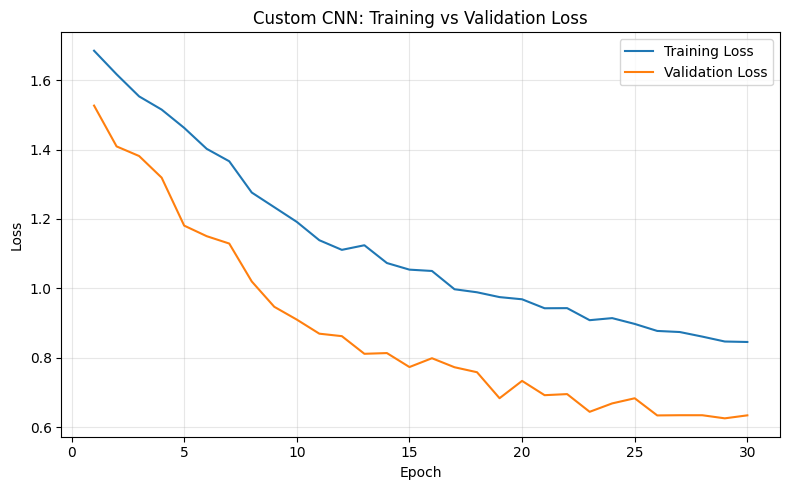

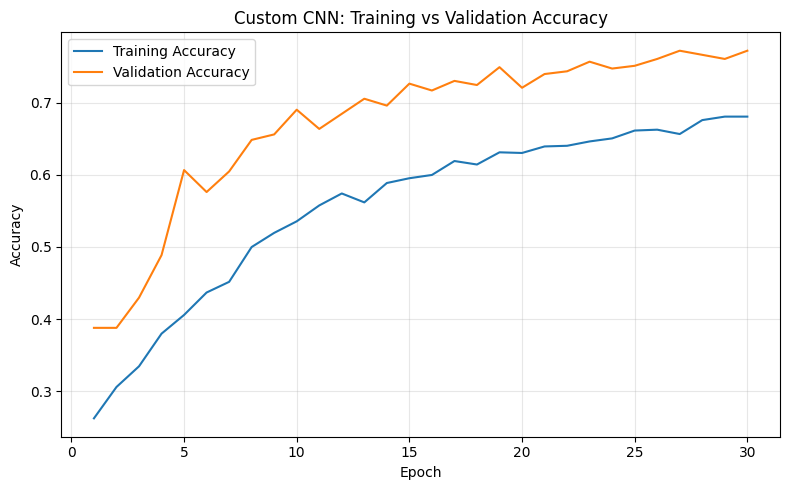

In [42]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history["loss"]) + 1)

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["loss"], label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN: Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Custom CNN: Training vs Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 2.35 Evaluating the Custom CNN on the Test Set

This step evaluates the trained Custom CNN on the held-out test set. The test set is used only for final evaluation to estimate the model's performance on unseen images.

In [43]:
test_loss, test_accuracy = custom_cnn.evaluate(
    test_dataset,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.7552 - loss: 0.6580
Test Loss: 0.6580
Test Accuracy: 75.52%


### 2.36 Evaluating Per-Class Performance

This step generates a classification report to measure precision, recall, and F1-score for each oral disease class. These metrics provide a more detailed evaluation than overall accuracy alone.

In [44]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy()
    for _, labels in test_dataset
])

y_prob = custom_cnn.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

class_names = label_encoder.classes_

print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step
                     precision    recall  f1-score   support

           Calculus     0.5833    0.6176    0.6000        68
             Caries     0.3333    0.1071    0.1622        28
         Gingivitis     0.8032    0.8118    0.8075       186
         Hypodontia     0.8820    0.8579    0.8698       183
        Mouth Ulcer     0.6905    0.8056    0.7436        36
Tooth Discoloration     0.4211    0.6154    0.5000        26

           accuracy                         0.7552       527
          macro avg     0.6189    0.6359    0.6138       527
       weighted avg     0.7507    0.7552    0.7485       527



### 2.37 Visualizing the Confusion Matrix

This step visualizes the classification results for each class. The confusion matrix helps identify which oral disease classes are frequently confused with one another.

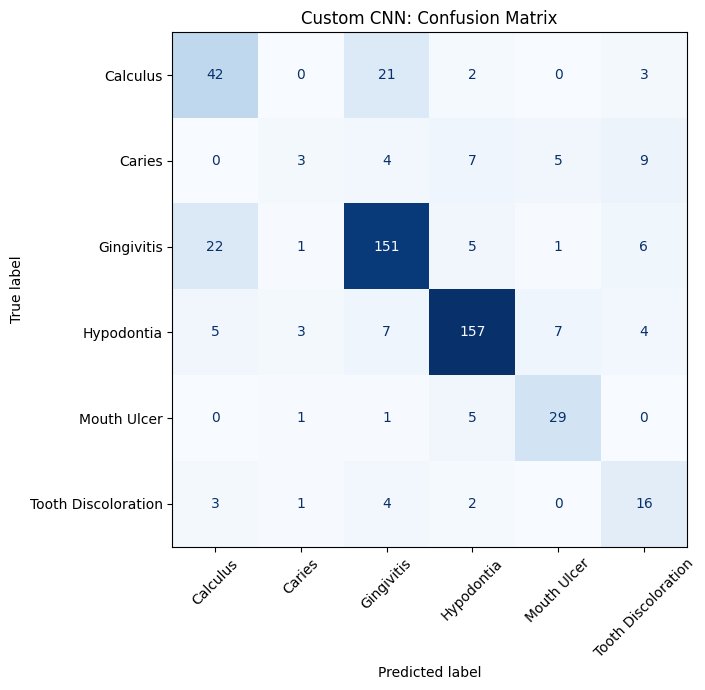

In [45]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("Custom CNN: Confusion Matrix")
plt.tight_layout()
plt.show()

### 2.38 Inspecting Misclassified Images

This step inspects test images that were misclassified by the Custom CNN. The goal is to identify possible visual similarities, ambiguous labels, or image-quality issues that may explain the model's errors.

Gingivitis images predicted as Calculus: 22


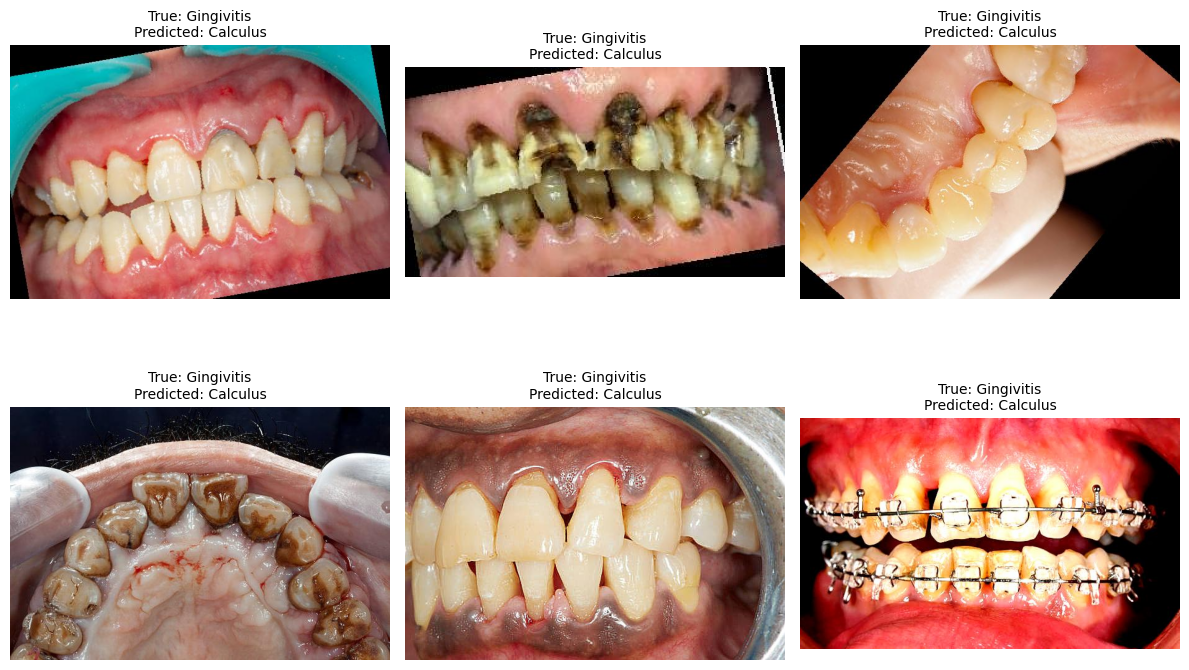

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Find test images where the true class is Gingivitis
# but the model predicted Calculus
target_true = label_encoder.transform(["Gingivitis"])[0]
target_pred = label_encoder.transform(["Calculus"])[0]

misclassified_indices = np.where(
    (y_true == target_true) & (y_pred == target_pred)
)[0]

print("Gingivitis images predicted as Calculus:",
      len(misclassified_indices))

# Collect test image paths in the same order as y_true
test_paths = test_df["path"].astype(str).to_numpy()

# Display up to 6 misclassified images
num_to_show = min(6, len(misclassified_indices))

fig, axes = plt.subplots(
    2, 3, figsize=(12, 8)
)
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for ax, idx in zip(axes, misclassified_indices[:num_to_show]):
    image = plt.imread(test_paths[idx])

    ax.imshow(image)
    ax.set_title(
        f"True: Gingivitis\nPredicted: Calculus",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


### 2.39 Preparing MobileNetV2 Transfer Learning

This step prepares a pretrained MobileNetV2 backbone for oral disease image classification. The pretrained feature extractor will initially remain frozen while a new classification head is trained on the training dataset.

In [49]:
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
NUM_CLASSES = len(class_folders)

base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))

x = data_augmentation(inputs)

x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

transfer_model = keras.Model(
    inputs,
    outputs,
    name="mobilenetv2_transfer_learning"
)

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

transfer_model.summary()

Model: "mobilenetv2_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### 2.40 Configuring Transfer Learning Training

This step configures callbacks for the MobileNetV2 transfer learning model. Early stopping monitors validation loss, while model checkpointing preserves the best-performing model.

In [50]:
from pathlib import Path

transfer_checkpoint_dir = Path(
    "/kaggle/working/oral_disease_models"
)
transfer_checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

transfer_checkpoint_path = (
    transfer_checkpoint_dir / "mobilenetv2_best.keras"
)

transfer_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(transfer_checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

### 2.42 Training the MobileNetV2 Transfer Learning Model

This step trains the classification head while keeping the pretrained MobileNetV2 backbone frozen. Early stopping and model checkpointing help preserve the best model based on validation loss.

In [51]:
TRANSFER_EPOCHS = 20

transfer_history = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=TRANSFER_EPOCHS,
    callbacks=transfer_callbacks
)

Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.3871 - loss: 1.6940
Epoch 1: val_loss improved from None to 0.72051, saving model to /kaggle/working/oral_disease_models/mobilenetv2_best.keras

Epoch 1: finished saving model to /kaggle/working/oral_disease_models/mobilenetv2_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 15s 94ms/step - accuracy: 0.5198 - loss: 1.3188 - val_accuracy: 0.7624 - val_loss: 0.7205
Epoch 2/20
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.6916 - loss: 0.8106
Epoch 2: val_loss improved from 0.72051 to 0.62939, saving model to /kaggle/working/oral_disease_models/mobilenetv2_best.keras

Epoch 2: finished saving model to /kaggle/working/oral_disease_models/mobilenetv2_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.6977 - loss: 0.8006 - val_accuracy: 0.7738 - val_loss: 0.6294
Epoch 3/20
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7443 - loss: 0.6928
Epoch 3: val_loss improved from 0.62939 to 0.55556, saving mode

### 2.43 Evaluating the Transfer Learning Model

This step evaluates the trained MobileNetV2 model on the held-out test dataset to measure its performance on unseen images.

In [52]:
transfer_test_loss, transfer_test_accuracy = (
    transfer_model.evaluate(
        test_dataset,
        verbose=1
    )
)

print(f"Transfer Learning Test Loss: {transfer_test_loss:.4f}")
print(f"Transfer Learning Test Accuracy: {transfer_test_accuracy:.4%}")

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step - accuracy: 0.8861 - loss: 0.3435
Transfer Learning Test Loss: 0.3435
Transfer Learning Test Accuracy: 88.6148%


### 2.44 Classification Report for MobileNetV2

This step evaluates precision, recall, and F1-score for each oral disease class using predictions on the held-out test dataset.

In [53]:
from sklearn.metrics import classification_report

transfer_y_prob = transfer_model.predict(
    test_dataset,
    verbose=1
)

transfer_y_pred = transfer_y_prob.argmax(axis=1)

print(
    classification_report(
        y_true,
        transfer_y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
                     precision    recall  f1-score   support

           Calculus     0.8333    0.7353    0.7812        68
             Caries     0.8095    0.6071    0.6939        28
         Gingivitis     0.8495    0.9409    0.8929       186
         Hypodontia     0.9556    0.9399    0.9477       183
        Mouth Ulcer     0.9730    1.0000    0.9863        36
Tooth Discoloration     0.7391    0.6538    0.6939        26

           accuracy                         0.8861       527
          macro avg     0.8600    0.8128    0.8326       527
       weighted avg     0.8851    0.8861    0.8835       527



### 2.45 Confusion Matrix for MobileNetV2

This step visualizes the model's predictions against the true labels to identify which oral disease classes are most frequently confused.

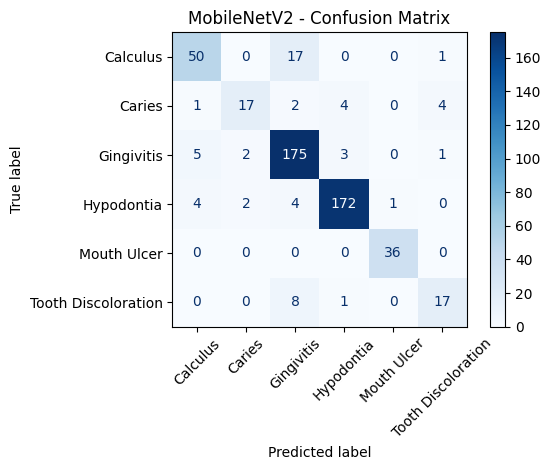

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_true,
    transfer_y_pred,
    labels=range(len(class_names)),
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout()
plt.show()

### 2.46 Comparing Custom CNN and Transfer Learning

This step compares both models using their test accuracy and test loss to evaluate the benefit of transfer learning on the oral disease classification task.

In [55]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2 Transfer Learning"],
    "Test Accuracy": [
        test_accuracy,
        transfer_test_accuracy
    ],
    "Test Loss": [
        test_loss,
        transfer_test_loss
    ]
})

comparison_df["Test Accuracy (%)"] = (
    comparison_df["Test Accuracy"] * 100
).round(2)

comparison_df["Test Loss"] = comparison_df["Test Loss"].round(4)

comparison_df[
    ["Model", "Test Accuracy (%)", "Test Loss"]
]

,Model,Test Accuracy (%),Test Loss
0,Custom CNN,75.52,0.6580
1,MobileNetV2 Transfer Learning,88.61,0.3435


### 2.47 Visual Comparison of Model Performance

This step visualizes test accuracy and test loss for the Custom CNN and MobileNetV2 Transfer Learning models using separate charts for a clear comparison.

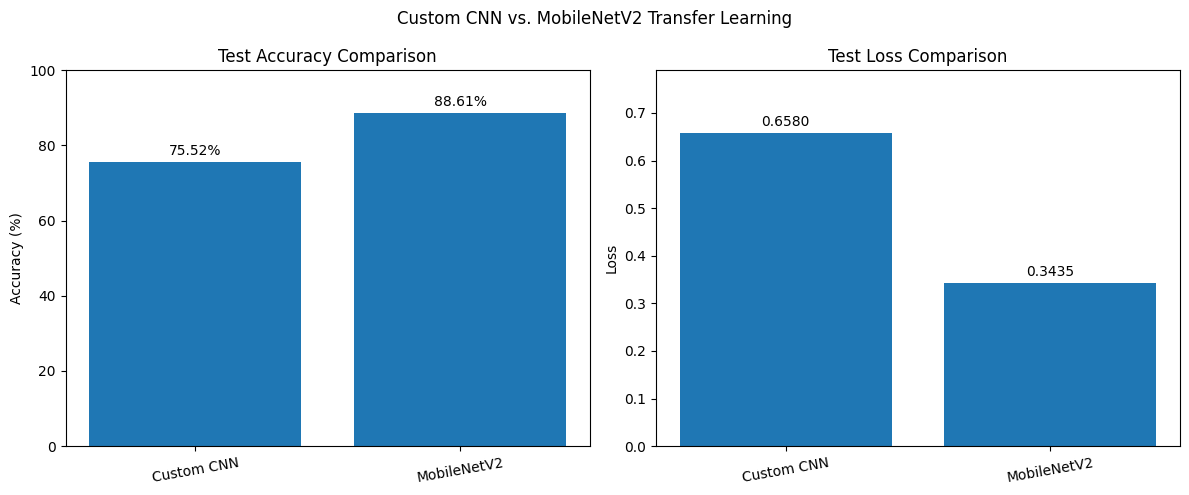

In [56]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Custom CNN", "MobileNetV2"]
test_accuracies = [75.52, 88.61]
test_losses = [0.6580, 0.3435]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Test Accuracy
bars1 = axes[0].bar(models, test_accuracies)
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)

axes[0].bar_label(bars1, fmt="%.2f%%", padding=3)
axes[0].tick_params(axis="x", rotation=10)

# Test Loss
bars2 = axes[1].bar(models, test_losses)
axes[1].set_title("Test Loss Comparison")
axes[1].set_ylabel("Loss")
axes[1].set_ylim(0, max(test_losses) * 1.2)

axes[1].bar_label(bars2, fmt="%.4f", padding=3)
axes[1].tick_params(axis="x", rotation=10)

plt.suptitle("Custom CNN vs. MobileNetV2 Transfer Learning")
plt.tight_layout()
plt.show()

### 2.48 Building the EfficientNetB0 Transfer Learning Model

This step loads EfficientNetB0 with pretrained ImageNet weights, freezes its backbone, and adds a new classification head for the six oral disease classes.

In [57]:
from tensorflow import keras
from tensorflow.keras import layers

IMG_SIZE = (224, 224)
NUM_CLASSES = len(class_folders)

efficientnet_base = keras.applications.EfficientNetB0(
    input_shape=(*IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

efficientnet_base.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))

x = data_augmentation(inputs)

# EfficientNetB0 in Keras includes input rescaling internally.
x = efficientnet_base(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

efficientnet_model = keras.Model(
    inputs,
    outputs,
    name="efficientnetb0_transfer_learning"
)

efficientnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_transfer_learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,057,257 (15.48 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

### 2.49 Configuring EfficientNetB0 Training Callbacks

This step configures early stopping and model checkpointing to monitor validation loss and preserve the best-performing EfficientNetB0 model.

In [58]:
from pathlib import Path

efficientnet_checkpoint_dir = Path(
    "/kaggle/working/oral_disease_models"
)
efficientnet_checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True
)

efficientnet_checkpoint_path = (
    efficientnet_checkpoint_dir / "efficientnetb0_best.keras"
)

efficientnet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(efficientnet_checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

### 2.50 Training the EfficientNetB0 Transfer Learning Model

This step trains the EfficientNetB0 classification head using the training dataset, monitors validation performance, and saves the best model based on validation loss.

In [59]:
EFFICIENTNET_EPOCHS = 20

efficientnet_history = efficientnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EFFICIENTNET_EPOCHS,
    callbacks=efficientnet_callbacks
)

Epoch 1/20


E0000 00:00:1792853736.522141      48 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/efficientnetb0_transfer_learning_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.4126 - loss: 1.4984
Epoch 1: val_loss improved from None to 0.74388, saving model to /kaggle/working/oral_disease_models/efficientnetb0_best.keras

Epoch 1: finished saving model to /kaggle/working/oral_disease_models/efficientnetb0_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 129ms/step - accuracy: 0.5466 - loss: 1.2310 - val_accuracy: 0.7567 - val_loss: 0.7439
Epoch 2/20
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.6961 - loss: 0.8644
Epoch 2: val_loss improved from 0.74388 to 0.60408, saving model to /kaggle/working/oral_disease_models/efficientnetb0_best.keras

Epoch 2: finished saving model to /kaggle/working/oral_disease_models/efficientnetb0_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.7137 - loss: 0.8200 - val_accuracy: 0.7966 - val_loss: 0.6041
Epoch 3/20
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.7611 - loss: 0.7033
Epoch 3: val_loss improved from 0.60408 to 0.53543, saving m

### 2.51 Evaluating EfficientNetB0 on the Test Dataset

This step evaluates the trained EfficientNetB0 model on the independent test dataset to measure its generalization performance using test loss and test accuracy.

In [60]:
efficientnet_test_loss, efficientnet_test_accuracy = (
    efficientnet_model.evaluate(test_dataset, verbose=1)
)

print(f"EfficientNetB0 Test Loss: {efficientnet_test_loss:.4f}")
print(f"EfficientNetB0 Test Accuracy: {efficientnet_test_accuracy:.4%}")

17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accuracy: 0.8691 - loss: 0.3314
EfficientNetB0 Test Loss: 0.3314
EfficientNetB0 Test Accuracy: 86.9070%


### 2.52 Generating the EfficientNetB0 Classification Report

This step generates a classification report for EfficientNetB0 using the test dataset to evaluate precision, recall, and F1-score for each oral disease class.

In [61]:
from sklearn.metrics import classification_report
import numpy as np

efficientnet_y_prob = efficientnet_model.predict(test_dataset, verbose=1)
efficientnet_y_pred = np.argmax(efficientnet_y_prob, axis=1)

print(
    classification_report(
        y_true,
        efficientnet_y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

17/17 ━━━━━━━━━━━━━━━━━━━━ 5s 202ms/step
                     precision    recall  f1-score   support

           Calculus     0.9000    0.6618    0.7627        68
             Caries     0.4783    0.3929    0.4314        28
         Gingivitis     0.8389    0.9516    0.8917       186
         Hypodontia     0.9607    0.9344    0.9474       183
        Mouth Ulcer     0.8974    0.9722    0.9333        36
Tooth Discoloration     0.7308    0.7308    0.7308        26

           accuracy                         0.8691       527
          macro avg     0.8010    0.7739    0.7829       527
       weighted avg     0.8686    0.8691    0.8648       527



### 2.53 Generating the EfficientNetB0 Confusion Matrix

This step visualizes the confusion matrix for EfficientNetB0 on the test dataset to identify correct predictions and common classification errors across the six oral disease classes.

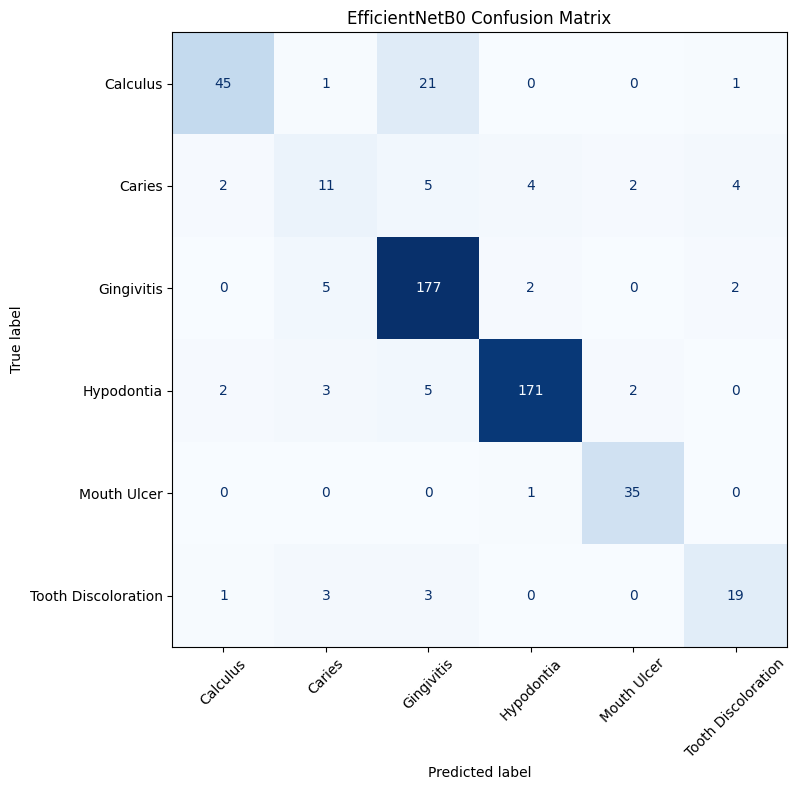

In [62]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

efficientnet_cm = confusion_matrix(
    y_true,
    efficientnet_y_pred,
    labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=efficientnet_cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("EfficientNetB0 Confusion Matrix")
plt.tight_layout()
plt.show()

### 2.54 Comparing the Three Models

This step compares Custom CNN, MobileNetV2, and EfficientNetB0 using their test accuracy and test loss to identify the best-performing model on the held-out test dataset.

In [63]:
model_names = [
    "Custom CNN",
    "MobileNetV2",
    "EfficientNetB0"
]

test_accuracies = [
    test_accuracy,
    transfer_test_accuracy,
    efficientnet_test_accuracy
]

test_losses = [
    test_loss,
    transfer_test_loss,
    efficientnet_test_loss
]

for name, accuracy, loss in zip(
    model_names, test_accuracies, test_losses
):
    print(
        f"{name}: "
        f"Test Accuracy = {accuracy:.4%}, "
        f"Test Loss = {loss:.4f}"
    )

Custom CNN: Test Accuracy = 75.5218%, Test Loss = 0.6580
MobileNetV2: Test Accuracy = 88.6148%, Test Loss = 0.3435
EfficientNetB0: Test Accuracy = 86.9070%, Test Loss = 0.3314


### 2.55 Visual Comparison of the Three Models

This step visualizes the test accuracy and test loss of Custom CNN, MobileNetV2, and EfficientNetB0 to compare their classification performance on the same test dataset.

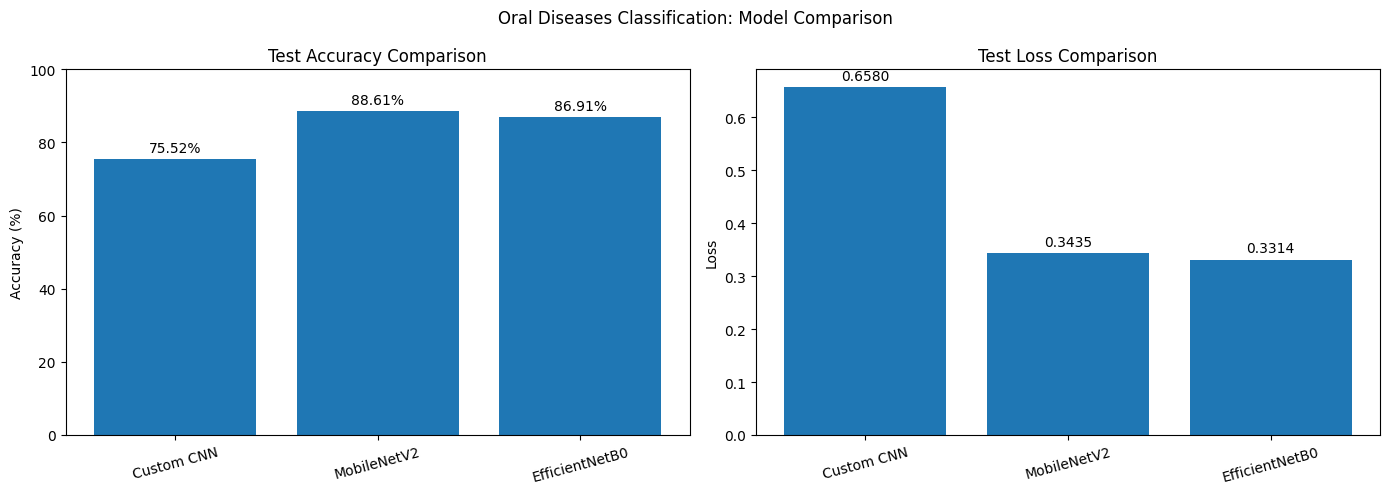

In [64]:
import matplotlib.pyplot as plt
import numpy as np

model_names = [
    "Custom CNN",
    "MobileNetV2",
    "EfficientNetB0"
]

test_accuracies = [
    test_accuracy * 100,
    transfer_test_accuracy * 100,
    efficientnet_test_accuracy * 100
]

test_losses = [
    test_loss,
    transfer_test_loss,
    efficientnet_test_loss
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Test Accuracy
bars1 = axes[0].bar(model_names, test_accuracies)
axes[0].set_title("Test Accuracy Comparison")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 100)
axes[0].bar_label(bars1, fmt="%.2f%%", padding=3)
axes[0].tick_params(axis="x", rotation=15)

# Test Loss
bars2 = axes[1].bar(model_names, test_losses)
axes[1].set_title("Test Loss Comparison")
axes[1].set_ylabel("Loss")
axes[1].bar_label(bars2, fmt="%.4f", padding=3)
axes[1].tick_params(axis="x", rotation=15)

plt.suptitle("Oral Diseases Classification: Model Comparison")
plt.tight_layout()
plt.show()

### 2.56 Comparing Per-Class F1-Scores

This step compares the F1-score of Custom CNN, MobileNetV2, and EfficientNetB0 for each oral disease class to identify their strengths and weaknesses across the dataset.

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 50ms/step
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step


,Custom CNN,MobileNetV2,EfficientNetB0
Calculus,0.6000,0.7812,0.7627
Caries,0.1622,0.6939,0.4314
Gingivitis,0.8075,0.8929,0.8917
Hypodontia,0.8698,0.9477,0.9474
Mouth Ulcer,0.7436,0.9863,0.9333
Tooth Discoloration,0.5000,0.6939,0.7308


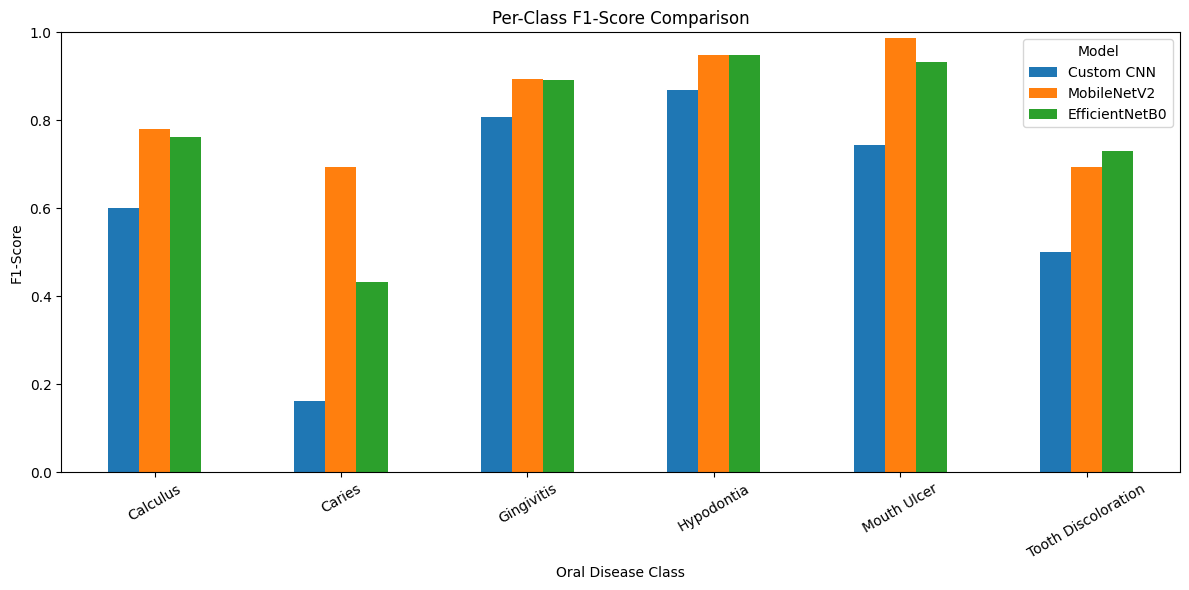

In [65]:
from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Generate predictions for all three models
custom_cnn_probs = custom_cnn.predict(test_dataset, verbose=1)
custom_cnn_preds = np.argmax(custom_cnn_probs, axis=1)

mobilenet_probs = transfer_model.predict(test_dataset, verbose=1)
mobilenet_preds = np.argmax(mobilenet_probs, axis=1)

efficientnet_probs = efficientnet_model.predict(test_dataset, verbose=1)
efficientnet_preds = np.argmax(efficientnet_probs, axis=1)

# Extract per-class F1-scores
model_predictions = {
    "Custom CNN": custom_cnn_preds,
    "MobileNetV2": mobilenet_preds,
    "EfficientNetB0": efficientnet_preds
}

f1_comparison = {}

for model_name, predictions in model_predictions.items():
    report = classification_report(
        y_true,
        predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    f1_comparison[model_name] = {
        class_name: report[class_name]["f1-score"]
        for class_name in class_names
    }

f1_df = pd.DataFrame(f1_comparison)
display(f1_df.round(4))

# Plot the comparison
ax = f1_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Per-Class F1-Score Comparison")
ax.set_xlabel("Oral Disease Class")
ax.set_ylabel("F1-Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Model")
plt.tight_layout()
plt.show()

### 2.57 Comparing Overall Precision, Recall, and F1-Score

This step compares the macro-averaged precision, recall, and F1-score of the three models to evaluate their overall performance while giving equal importance to each oral disease class.

In [66]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

model_predictions = {
    "Custom CNN": custom_cnn_preds,
    "MobileNetV2": mobilenet_preds,
    "EfficientNetB0": efficientnet_preds
}

metrics_comparison = {}

for model_name, predictions in model_predictions.items():
    report = classification_report(
        y_true,
        predictions,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    metrics_comparison[model_name] = {
        "Macro Precision": report["macro avg"]["precision"],
        "Macro Recall": report["macro avg"]["recall"],
        "Macro F1-Score": report["macro avg"]["f1-score"]
    }

metrics_df = pd.DataFrame(metrics_comparison).T

display(
    (metrics_df * 100).round(2).rename_axis("Model")
)

,Macro Precision,Macro Recall,Macro F1-Score
Model,,,
Custom CNN,61.89,63.59,61.38
MobileNetV2,86.00,81.28,83.26
EfficientNetB0,80.10,77.39,78.29


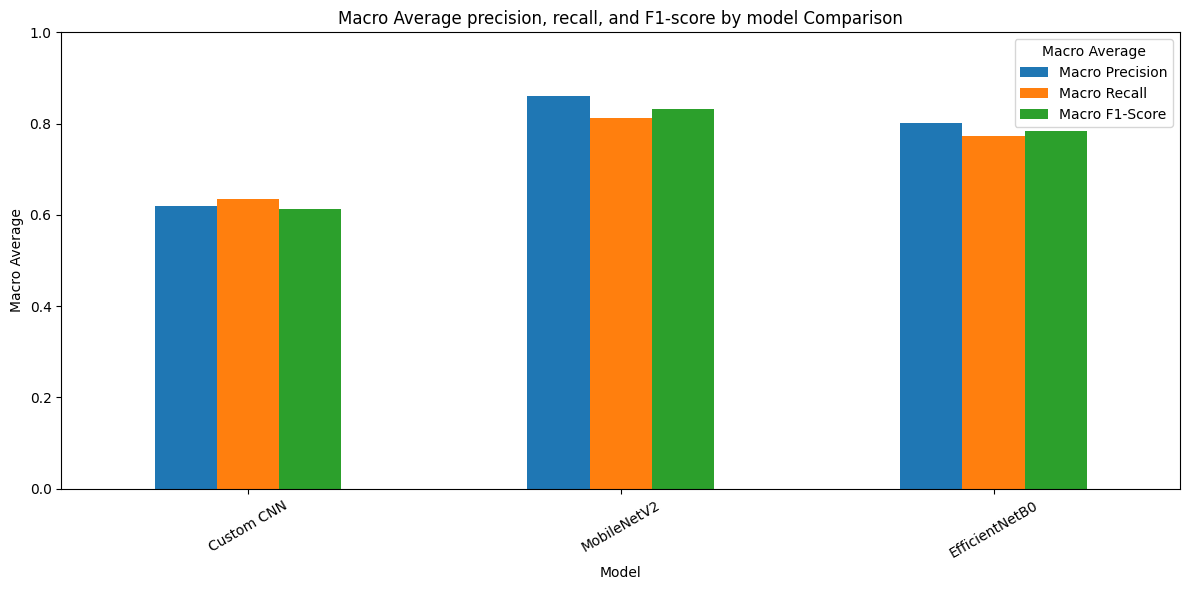

In [69]:
# Plot the comparison
ax = metrics_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Macro Average precision, recall, and F1-score by model Comparison")
ax.set_xlabel("Model")
ax.set_ylabel("Macro Average")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=30)
ax.legend(title="Macro Average")
plt.tight_layout()
plt.show()

### 2.58 Preparing MobileNetV2 for Fine-Tuning

Inspect the pretrained backbone and its layer structure before unfreezing selected layers for fine-tuning.

In [71]:
print("Backbone model:", base_model.name)
print("Total layers:", len(base_model.layers))
print("Backbone trainable:", base_model.trainable)

print("\nLast 10 layers:")
for layer in base_model.layers[-10:]:
    print(layer.name, "| Trainable:", layer.trainable)

Backbone model: mobilenetv2_1.00_224
Total layers: 154
Backbone trainable: False

Last 10 layers:
block_16_expand_BN | Trainable: False
block_16_expand_relu | Trainable: False
block_16_depthwise | Trainable: False
block_16_depthwise_BN | Trainable: False
block_16_depthwise_relu | Trainable: False
block_16_project | Trainable: False
block_16_project_BN | Trainable: False
Conv_1 | Trainable: False
Conv_1_bn | Trainable: False
out_relu | Trainable: False


### 2.59 Unfreezing Selected MobileNetV2 Layers

Unfreeze the last 30 layers of the pretrained backbone while keeping Batch Normalization layers frozen.

In [72]:
# Keep the backbone frozen initially
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(layer.trainable for layer in base_model.layers))
print("Frozen layers:", sum(not layer.trainable for layer in base_model.layers))

print("\nLast 30 layers:")
for layer in base_model.layers[-30:]:
    print(layer.name, "| Trainable:", layer.trainable)

Total layers: 154
Trainable layers: 19
Frozen layers: 135

Last 30 layers:
block_13_project_BN | Trainable: False
block_14_expand | Trainable: True
block_14_expand_BN | Trainable: False
block_14_expand_relu | Trainable: True
block_14_depthwise | Trainable: True
block_14_depthwise_BN | Trainable: False
block_14_depthwise_relu | Trainable: True
block_14_project | Trainable: True
block_14_project_BN | Trainable: False
block_14_add | Trainable: True
block_15_expand | Trainable: True
block_15_expand_BN | Trainable: False
block_15_expand_relu | Trainable: True
block_15_depthwise | Trainable: True
block_15_depthwise_BN | Trainable: False
block_15_depthwise_relu | Trainable: True
block_15_project | Trainable: True
block_15_project_BN | Trainable: False
block_15_add | Trainable: True
block_16_expand | Trainable: True
block_16_expand_BN | Trainable: False
block_16_expand_relu | Trainable: True
block_16_depthwise | Trainable: True
block_16_depthwise_BN | Trainable: False
block_16_depthwise_relu |

### 2.60 Recompiling MobileNetV2 for Fine-Tuning

Recompile the model with a lower learning rate to make small, controlled updates to the unfrozen pretrained layers.

In [73]:
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Optimizer:", type(transfer_model.optimizer).__name__)
print("Learning rate:", float(transfer_model.optimizer.learning_rate.numpy()))
print("Trainable model parameters:",
      sum(
          int(tf.size(variable).numpy())
          for variable in transfer_model.trainable_variables
      ))

Optimizer: Adam
Learning rate: 9.999999747378752e-06
Trainable model parameters: 1518406


### 2.61 Fine-Tuning MobileNetV2

Fine-tune the selected pretrained layers using a low learning rate and validation-based callbacks to monitor generalization and prevent unnecessary training.

In [74]:
fine_tune_checkpoint_path = (
    transfer_checkpoint_dir / "mobilenetv2_finetuned_best.keras"
)

fine_tune_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(fine_tune_checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

fine_tune_history = transfer_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=15,
    callbacks=fine_tune_callbacks
)

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.8808 - loss: 0.3278
Epoch 1: val_loss improved from None to 0.37671, saving model to /kaggle/working/oral_disease_models/mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to /kaggle/working/oral_disease_models/mobilenetv2_finetuned_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 15s 93ms/step - accuracy: 0.8893 - loss: 0.3022 - val_accuracy: 0.8593 - val_loss: 0.3767
Epoch 2/15
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9080 - loss: 0.2846
Epoch 2: val_loss improved from 0.37671 to 0.33193, saving model to /kaggle/working/oral_disease_models/mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to /kaggle/working/oral_disease_models/mobilenetv2_finetuned_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step - accuracy: 0.9041 - loss: 0.2825 - val_accuracy: 0.8745 - val_loss: 0.3319
Epoch 3/15
103/104 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.9124 - loss: 0.2455
Epoch 3: val_loss impro

### 2.62 Evaluating Fine-Tuned MobileNetV2

Evaluate the fine-tuned model on the test dataset and record its final loss and accuracy.

In [75]:
fine_tune_test_loss, fine_tune_test_accuracy = transfer_model.evaluate(
    test_dataset,
    verbose=1
)

print(f"Fine-Tuned MobileNetV2 Test Loss: {fine_tune_test_loss:.4f}")
print(f"Fine-Tuned MobileNetV2 Test Accuracy: {fine_tune_test_accuracy * 100:.2f}%")

17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.9203 - loss: 0.2580
Fine-Tuned MobileNetV2 Test Loss: 0.2580
Fine-Tuned MobileNetV2 Test Accuracy: 92.03%


### 2.63 Comparing All Model Variants

Compare the test accuracy and test loss of the custom CNN, the original transfer learning models, and the fine-tuned MobileNetV2.

In [76]:
import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "MobileNetV2",
        "EfficientNetB0",
        "MobileNetV2 Fine-Tuned"
    ],
    "Test Accuracy (%)": [
        75.5218,
        88.6148,
        86.9070,
        fine_tune_test_accuracy * 100
    ],
    "Test Loss": [
        0.6580,
        0.3435,
        0.3314,
        fine_tune_test_loss
    ]
})

model_comparison = model_comparison.sort_values(
    "Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

model_comparison


,Model,Test Accuracy (%),Test Loss
0,MobileNetV2 Fine-Tuned,92.030358,0.258024
1,MobileNetV2,88.614800,0.343500
2,EfficientNetB0,86.907000,0.331400
3,Custom CNN,75.521800,0.658000


### 2.64 Visual Comparison of All Model Variants

Compare the test accuracy and test loss of the four model variants to identify their relative performance.

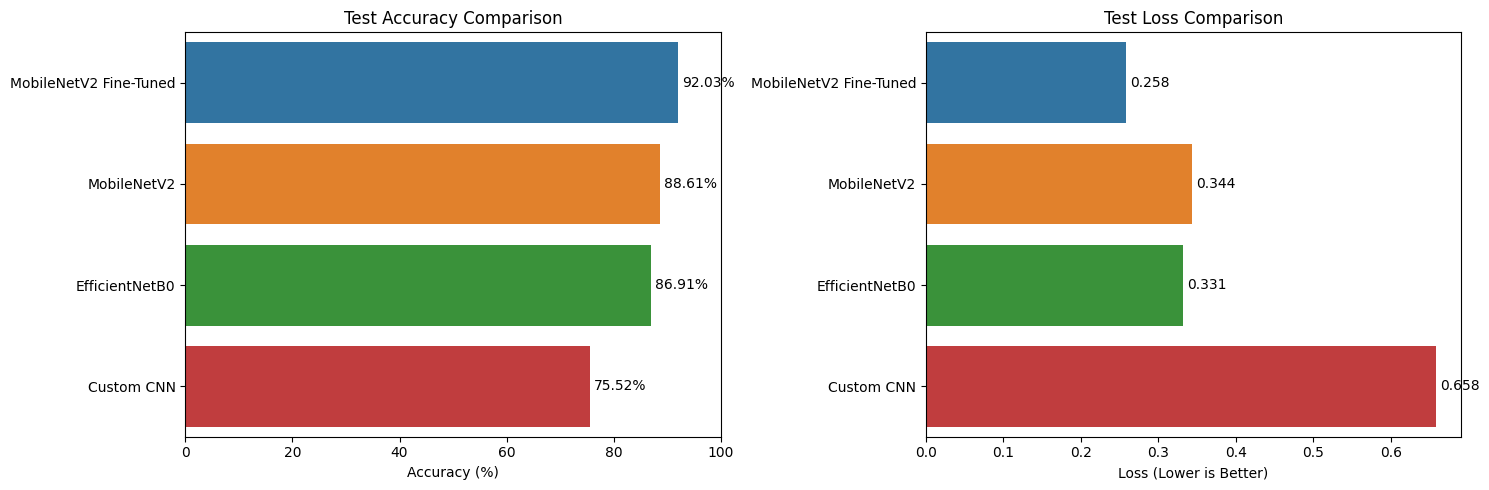

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(
    data=model_comparison,
    x="Test Accuracy (%)",
    y="Model",
    hue="Model",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Test Accuracy Comparison")
axes[0].set_xlabel("Accuracy (%)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 100)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.2f%%", padding=3)

sns.barplot(
    data=model_comparison,
    x="Test Loss",
    y="Model",
    hue="Model",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("Test Loss Comparison")
axes[1].set_xlabel("Loss (Lower is Better)")
axes[1].set_ylabel("")

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

### 2.65 Classification Report for Fine-Tuned MobileNetV2

Evaluate per-class precision, recall, and F1-score to understand the strengths and weaknesses of the fine-tuned model across all oral disease categories.

In [78]:
from sklearn.metrics import classification_report
import numpy as np

y_pred_proba_finetuned = transfer_model.predict(test_dataset, verbose=1)
y_pred_finetuned = np.argmax(y_pred_proba_finetuned, axis=1)

print(
    classification_report(
        y_true,
        y_pred_finetuned,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

17/17 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step
                     precision    recall  f1-score   support

           Calculus     0.9091    0.8824    0.8955        68
             Caries     0.8000    0.7143    0.7547        28
         Gingivitis     0.8995    0.9624    0.9299       186
         Hypodontia     0.9830    0.9454    0.9638       183
        Mouth Ulcer     0.9000    1.0000    0.9474        36
Tooth Discoloration     0.8095    0.6538    0.7234        26

           accuracy                         0.9203       527
          macro avg     0.8835    0.8597    0.8691       527
       weighted avg     0.9200    0.9203    0.9189       527



### 2.65 Classification Report for Fine-Tuned MobileNetV2


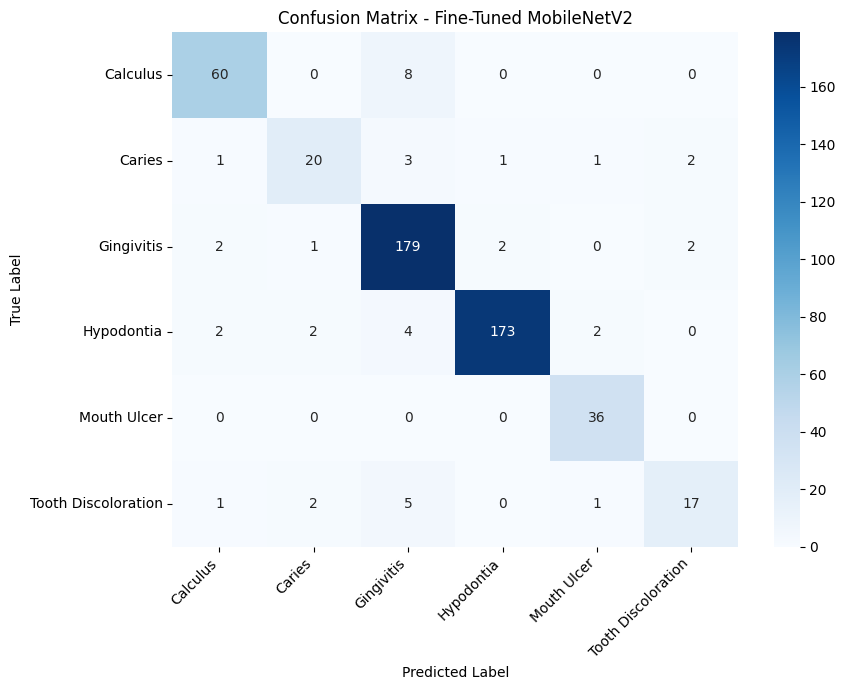

In [80]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_finetuned = confusion_matrix(
    y_true,
    y_pred_finetuned,
    labels=range(len(class_names))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_finetuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Fine-Tuned MobileNetV2")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### 2.67 Final Model Selection

Based on the comparative evaluation, the fine-tuned MobileNetV2 model was selected as the best-performing model among the four evaluated variants.

It achieved a test accuracy of **92.03%** and a test loss of **0.2580**, outperforming the original MobileNetV2, EfficientNetB0, and the custom CNN in test accuracy and test loss.

The classification report also showed strong performance across most classes, with an overall weighted F1-score of **91.89%**.

These results indicate that fine-tuning pretrained layers improved the model's performance on this dataset. However, the test set was used during earlier model comparisons, so the reported test metrics should not be considered a fully independent final estimate of generalization performance.

This model is intended for research and educational purposes, not as a standalone tool for medical diagnosis.

### 2.68 Saving the Final Model

Save the selected fine-tuned MobileNetV2 model in Keras format for future inference, evaluation, and deployment.

In [81]:
final_model_path = "/kaggle/working/oral_disease_models/oral_disease_classifier.keras"

transfer_model.save(final_model_path)

print("Model saved successfully.")
print("Saved path:", final_model_path)

Model saved successfully.
Saved path: /kaggle/working/oral_disease_models/oral_disease_classifier.keras


### 2.69 Verifying the Saved Model

Verify that the final model file exists and has a non-zero file size.

In [82]:
from pathlib import Path

saved_model = Path(final_model_path)

if saved_model.exists() and saved_model.stat().st_size > 0:
    print("Verification successful.")
    print(f"File size: {saved_model.stat().st_size / (1024 * 1024):.2f} MB")
else:
    print("Model file was not saved correctly.")

Verification successful.
File size: 20.81 MB


### 2.70 Loading and Verifying the Saved Model

Reload the saved fine-tuned MobileNetV2 model to verify that it can be restored and used for inference.

In [83]:
loaded_model = keras.models.load_model(final_model_path)

print("Model loaded successfully.")
print("Model name:", loaded_model.name)
print("Input shape:", loaded_model.input_shape)
print("Output shape:", loaded_model.output_shape)

Model loaded successfully.
Model name: mobilenetv2_transfer_learning
Input shape: (None, 224, 224, 3)
Output shape: (None, 6)


### 2.71 Testing Inference with the Saved Model

Run inference on a sample test image using the reloaded model and display the predicted class and confidence score.

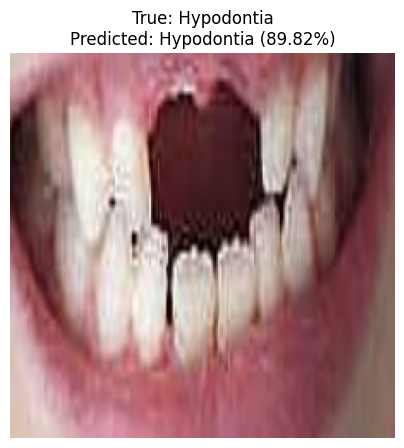

True class: Hypodontia
Predicted class: Hypodontia
Confidence: 89.82%


In [84]:
import numpy as np
import matplotlib.pyplot as plt

# Get one batch from the test dataset
sample_images, sample_labels = next(iter(test_dataset))

# Select one image
sample_image = sample_images[0]
true_label = int(sample_labels[0].numpy())

# Predict using the saved model
prediction = loaded_model.predict(
    tf.expand_dims(sample_image, axis=0),
    verbose=0
)[0]

predicted_label = int(np.argmax(prediction))
confidence = float(prediction[predicted_label]) * 100

# Display the image and prediction
plt.figure(figsize=(5, 5))
plt.imshow(np.clip(sample_image.numpy() / 255.0, 0, 1))
plt.title(
    f"True: {class_names[true_label]}\n"
    f"Predicted: {class_names[predicted_label]} ({confidence:.2f}%)"
)
plt.axis("off")
plt.show()

print("True class:", class_names[true_label])
print("Predicted class:", class_names[predicted_label])
print(f"Confidence: {confidence:.2f}%")

### 2.72 Project Summary

This project developed and compared deep learning models for oral disease image classification across six classes: Calculus, Caries, Gingivitis, Hypodontia, Mouth Ulcer, and Tooth Discoloration.

The workflow included dataset inspection, duplicate and cross-class conflict handling, stratified train-validation-test splitting, training-set oversampling, custom CNN development, transfer learning with MobileNetV2 and EfficientNetB0, and MobileNetV2 fine-tuning.

Four model variants were evaluated. The fine-tuned MobileNetV2 achieved the best recorded results:

- **Test Accuracy:** 92.03%
- **Test Loss:** 0.2580
- **Weighted F1-score:** 91.89%
- **Model Size:** Approximately 20.81 MB

The final model was saved in Keras format, reloaded successfully, and tested with a sample prediction.

**Limitations:** The test set was used during earlier model comparisons, so the reported test results are not a fully independent estimate of generalization. The model is intended for educational and research purposes and should not be used as a standalone medical diagnostic tool.

### 2.73 Reviewing Project Output Files

Inspect the generated files in the Kaggle working directory before preparing the project for publication.

In [85]:
from pathlib import Path

output_dir = Path("/kaggle/working")

for path in sorted(output_dir.iterdir()):
    if path.is_file():
        print(f"FILE: {path.name} | {path.stat().st_size / (1024 * 1024):.2f} MB")
    elif path.is_dir():
        print(f"FOLDER: {path.name}/")
        for file_path in sorted(path.iterdir()):
            if file_path.is_file():
                print(
                    f"    {file_path.name} | "
                    f"{file_path.stat().st_size / (1024 * 1024):.2f} MB"
                )

FOLDER: .virtual_documents/
    __notebook_source__.ipynb | 0.04 MB
FOLDER: oral_disease_models/
    custom_cnn_best.keras | 1.23 MB
    efficientnetb0_best.keras | 16.36 MB
    mobilenetv2_best.keras | 9.28 MB
    mobilenetv2_finetuned_best.keras | 20.81 MB
    oral_disease_classifier.keras | 20.81 MB
